# Frontière efficiente de Markowitz

**Abdou Bah** – Master Actuariat & Finance, Université de Rouen Normandie

## Objectif

Construire, à partir de quatre actions du CAC 40 (BNP Paribas, Société Générale, Danone, L'Oréal), la frontière efficiente de Markowitz sans vente à découvert, et la comparer à deux portefeuilles de référence : le portefeuille équipondéré et le portefeuille pondéré par la capitalisation boursière.

Un portefeuille de poids $w$ (avec $\sum_i w_i = 1$ et $w_i \geq 0$) a pour rendement espéré $\mu_p = w^\top \mu$ et pour variance $\sigma_p^2 = w^\top \Sigma\, w$, où $\mu$ est le vecteur des rendements espérés et $\Sigma$ la matrice de variance-covariance. Un portefeuille est efficient s'il n'existe aucun autre portefeuille de même rendement espéré avec une variance plus faible.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

plt.rcParams["figure.figsize"] = (8, 5)

## 1. Données

Cours de clôture quotidiens (source : BoursoBank), du 1er janvier 2021 au 31 décembre 2025. Les capitalisations boursières à fin 2025 viennent de companiesmarketcap.com.

Les cours sont des cours bruts : les dividendes ne sont pas inclus dans les rendements (voir les limites).

(1281, 4) | valeurs manquantes : 0


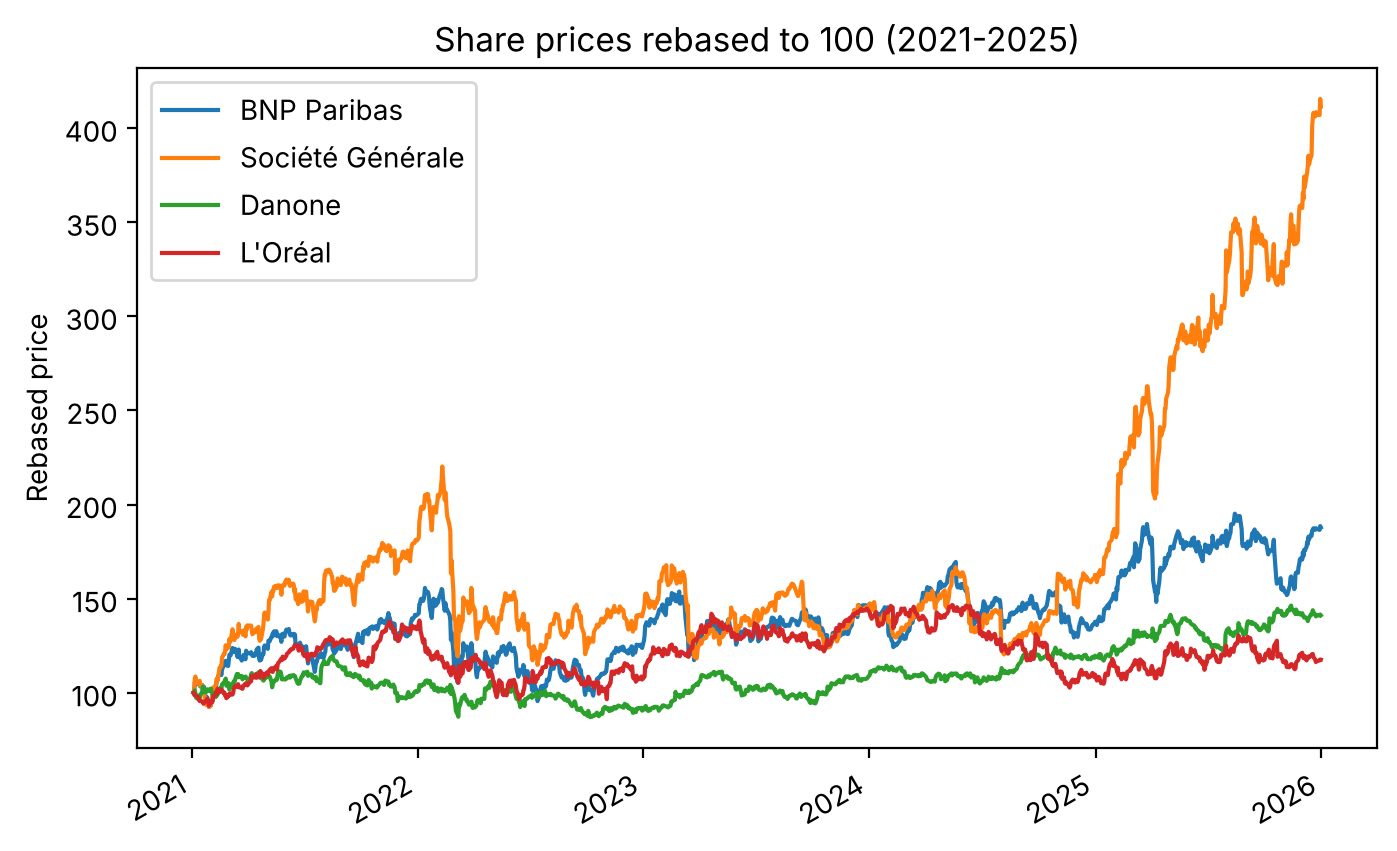

In [2]:
actions = ["BNP_PARIBAS", "SOCIETE_GENERALE", "DANONE", "LOREAL"]
noms = ["BNP Paribas", "Société Générale", "Danone", "L'Oréal"]

prix = pd.DataFrame({nom: pd.read_csv(f"data/{a}.csv", index_col="date", parse_dates=True)["clot"]
                     for a, nom in zip(actions, noms)}).sort_index()
prix = prix.loc["2021-01-01":"2025-12-31"]
print(prix.shape, "| valeurs manquantes :", prix.isna().sum().sum())

(prix / prix.iloc[0] * 100).plot(title="Share prices rebased to 100 (2021-2025)")
plt.ylabel("Rebased price")
plt.xlabel("")
plt.savefig("figures/prices.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Rendements et matrice de variance-covariance

Rendement quotidien $r_t = P_t / P_{t-1} - 1$. Les statistiques sont annualisées avec 252 jours de bourse : $\mu_{an} = 252\, \bar r$ et $\Sigma_{an} = 252\, \Sigma_{quot}$.

In [3]:
rendements = prix.pct_change().dropna()
mu = rendements.mean() * 252
Sigma = rendements.cov() * 252

pd.DataFrame({"rendement annuel (%)": mu * 100,
              "volatilité annuelle (%)": np.sqrt(np.diag(Sigma)) * 100}).round(1)

,rendement annuel (%),volatilité annuelle (%)
BNP Paribas,16.4,28.3
Société Générale,33.6,33.8
Danone,8.4,17.8
L'Oréal,5.9,23.4


In [4]:
rendements.corr().round(2)

,BNP Paribas,Société Générale,Danone,L'Oréal
BNP Paribas,1.00,0.78,0.22,0.31
Société Générale,0.78,1.00,0.22,0.26
Danone,0.22,0.22,1.00,0.31
L'Oréal,0.31,0.26,0.31,1.00


Les deux banques sont très corrélées entre elles et peu corrélées à Danone et L'Oréal. C'est cette structure que la matrice de covariance capte : combiner des actifs peu corrélés réduit la volatilité du portefeuille (diversification).

## 3. Portefeuilles de référence

- **Équipondéré** : 25 % sur chaque action.
- **Capitalisation** : poids proportionnels à la capitalisation boursière à fin 2025.

In [5]:
capitalisation = pd.Series([90.21, 51.66, 49.62, 194.63], index=noms)   # milliards d'euros, fin 2025

def performance(w, mu=mu, Sigma=Sigma):
    return w @ mu, np.sqrt(w @ Sigma @ w)

portefeuilles = {
    "Équipondéré": np.full(4, 0.25),
    "Capitalisation": (capitalisation / capitalisation.sum()).values,
}

## 4. Optimisation

### 4.1 Portefeuille de variance minimale

On minimise $w^\top \Sigma w$ sous les contraintes $\sum_i w_i = 1$ et $w_i \geq 0$ (pas de vente à découvert), avec l'algorithme SLSQP de `scipy`.

In [6]:
contrainte_budget = {"type": "eq", "fun": lambda w: w.sum() - 1}
bornes = [(0, 1)] * 4
w_depart = np.full(4, 0.25)

def variance_minimale(Sigma=Sigma):
    res = minimize(lambda w: w @ Sigma @ w, w_depart, method="SLSQP",
                   bounds=bornes, constraints=[contrainte_budget])
    return res.x

portefeuilles["Variance minimale"] = variance_minimale()

### 4.2 Frontière efficiente

Pour une suite de rendements cibles allant du rendement du portefeuille de variance minimale à celui de l'action la plus rentable, on cherche le portefeuille de variance minimale qui atteint exactement ce rendement.

In [7]:
def portefeuille_cible(rendement_cible, mu=mu, Sigma=Sigma):
    contraintes = [contrainte_budget, {"type": "eq", "fun": lambda w: w @ mu - rendement_cible}]
    res = minimize(lambda w: w @ Sigma @ w, w_depart, method="SLSQP", bounds=bornes, constraints=contraintes)
    return res.x

r_min = performance(portefeuilles["Variance minimale"])[0]
cibles = np.linspace(r_min, mu.max(), 40)
frontiere = np.array([portefeuille_cible(c) for c in cibles])
vol_frontiere = np.sqrt(np.einsum("ij,jk,ik->i", frontiere, Sigma.values, frontiere))

pd.DataFrame(frontiere[::8] * 100, columns=noms, index=[f"{c:.1%}" for c in cibles[::8]]).round(1)

,BNP Paribas,Société Générale,Danone,L'Oréal
9.1%,15.1,0.2,60.6,24.1
14.1%,0.9,24.1,57.2,17.8
19.1%,0.0,43.3,49.9,6.8
24.2%,0.0,62.6,37.4,0.0
29.2%,0.0,82.5,17.5,0.0


Le tableau donne la composition de quelques portefeuilles de la frontière (en %), par rendement cible. Le bas de la frontière est dominé par Danone et L'Oréal, les moins volatiles ; quand le rendement cible augmente, le poids de Société Générale, l'action la plus rentable sur la période, augmente jusqu'à 100 %.

### 4.3 Portefeuille de ratio de Sharpe maximal

Le ratio de Sharpe $(\mu_p - r_f) / \sigma_p$ mesure le rendement excédentaire par unité de risque. Le portefeuille qui le maximise est le point de tangence entre la frontière et une droite issue du taux sans risque. On prend $r_f = 2\,\%$, niveau du taux de dépôt de la BCE et de l'€STR fin 2025.

In [8]:
r_f = 0.02

def sharpe_maximal(mu=mu, Sigma=Sigma):
    res = minimize(lambda w: -(w @ mu - r_f) / np.sqrt(w @ Sigma @ w), w_depart, method="SLSQP",
                   bounds=bornes, constraints=[contrainte_budget])
    return res.x

portefeuilles["Sharpe maximal"] = sharpe_maximal()

tableau = pd.DataFrame(portefeuilles, index=noms).T * 100
tableau["rendement (%)"] = [performance(w)[0] * 100 for w in portefeuilles.values()]
tableau["volatilité (%)"] = [performance(w)[1] * 100 for w in portefeuilles.values()]
tableau["Sharpe"] = (tableau["rendement (%)"] / 100 - r_f) / (tableau["volatilité (%)"] / 100)
tableau.round(2)

,BNP Paribas,Société Générale,Danone,L'Oréal,rendement (%),volatilité (%),Sharpe
Équipondéré,25.00,25.00,25.00,25.00,16.09,19.15,0.74
Capitalisation,23.36,13.38,12.85,50.41,12.41,18.96,0.55
Variance minimale,15.76,0.00,60.52,23.71,9.06,15.51,0.46
Sharpe maximal,0.00,74.44,25.56,0.00,27.17,26.54,0.95


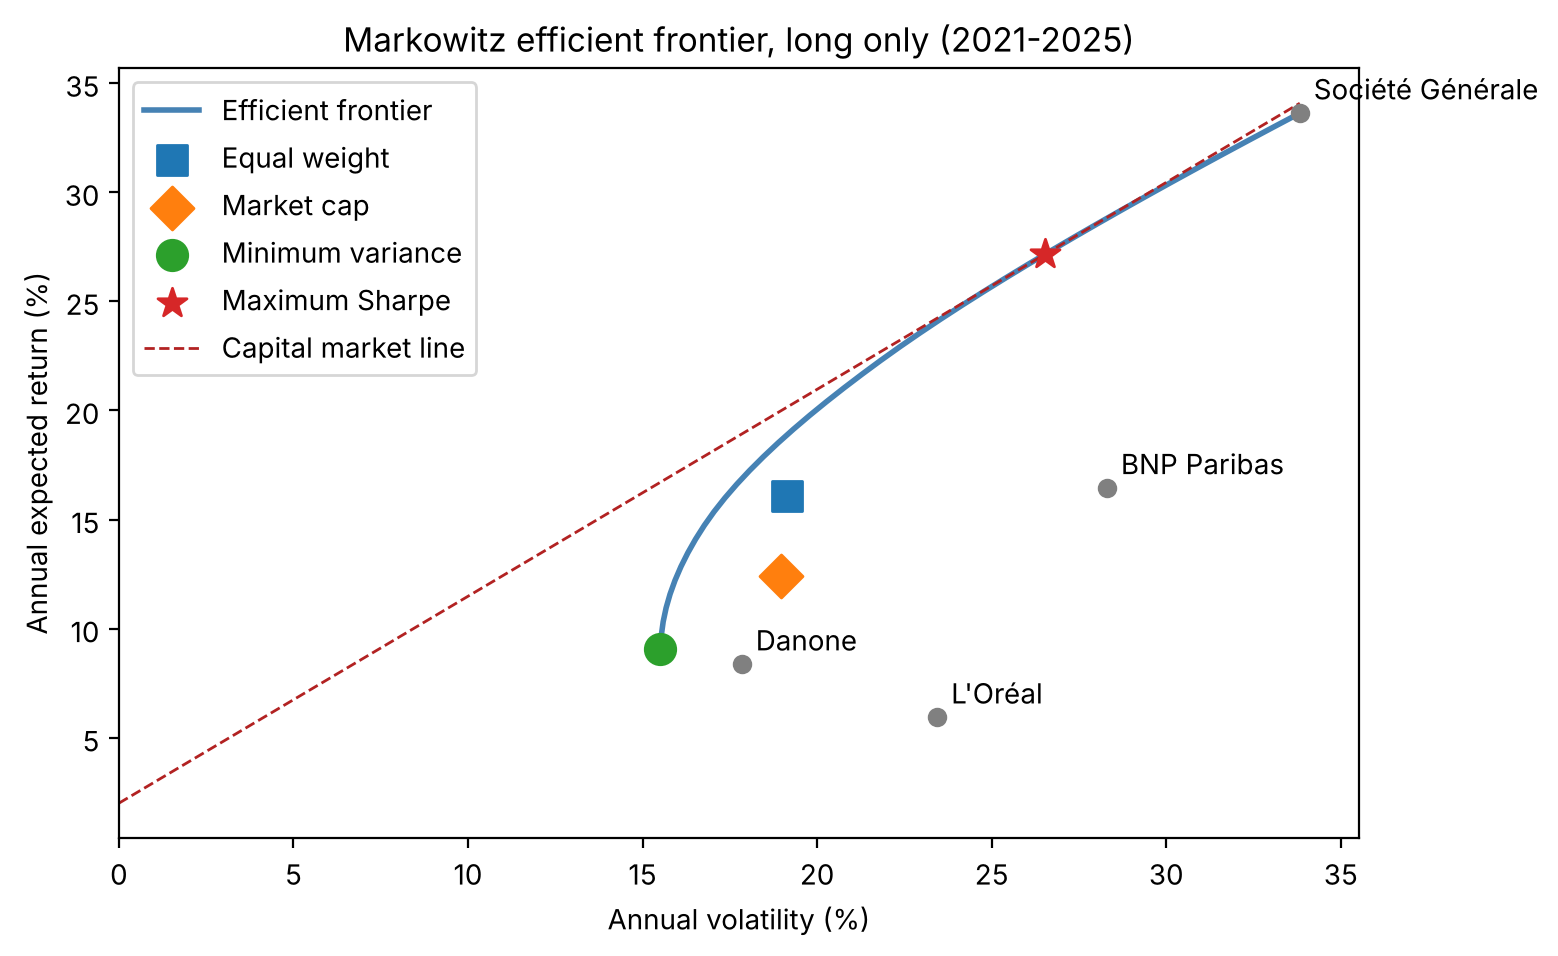

In [9]:
plt.plot(vol_frontiere * 100, cibles * 100, color="steelblue", lw=2, label="Efficient frontier")
plt.scatter(np.sqrt(np.diag(Sigma)) * 100, mu * 100, color="grey", zorder=3)
for nom, x, y in zip(noms, np.sqrt(np.diag(Sigma)) * 100, mu * 100):
    plt.annotate(nom, (x, y), textcoords="offset points", xytext=(5, 5))

marqueurs = {"Équipondéré": ("s", "Equal weight"), "Capitalisation": ("D", "Market cap"),
             "Variance minimale": ("o", "Minimum variance"), "Sharpe maximal": ("*", "Maximum Sharpe")}
for nom, (m, label) in marqueurs.items():
    r, v = performance(portefeuilles[nom])
    plt.scatter(v * 100, r * 100, marker=m, s=120, zorder=4, label=label)

v_t = performance(portefeuilles["Sharpe maximal"])[1]
r_t = performance(portefeuilles["Sharpe maximal"])[0]
x = np.linspace(0, vol_frontiere.max(), 50)
plt.plot(x * 100, (r_f + (r_t - r_f) / v_t * x) * 100, ls="--", color="firebrick", lw=1, label="Capital market line")

plt.xlabel("Annual volatility (%)")
plt.ylabel("Annual expected return (%)")
plt.title("Markowitz efficient frontier, long only (2021-2025)")
plt.xlim(0, None)
plt.legend()
plt.savefig("figures/efficient_frontier.png", dpi=150, bbox_inches="tight")
plt.show()

Les portefeuilles équipondéré et capitalisation sont sous la frontière : à volatilité égale, un portefeuille de la frontière aurait offert un rendement plus élevé sur la période.

## 5. Test hors échantillon

Les résultats ci-dessus sont calculés sur les données qui ont servi à construire les portefeuilles : ils sont forcément favorables à l'optimisation. Pour juger honnêtement la méthode, on estime $\mu$ et $\Sigma$ sur 2021-2024, on construit les portefeuilles au 31 décembre 2024, puis on mesure leur performance réelle en 2025 (poids maintenus constants).

Pour le portefeuille capitalisation, les capitalisations à fin 2024 sont approchées en multipliant celles de fin 2025 par l'évolution du cours en 2025 (nombre d'actions supposé constant).

In [10]:
r_2124 = rendements.loc[:"2024-12-31"]
r_2025 = rendements.loc["2025-01-01":]
mu_est = r_2124.mean() * 252
Sigma_est = r_2124.cov() * 252

evolution_2025 = prix.loc["2025-12-31":].iloc[-1] / prix.loc[:"2024-12-31"].iloc[-1]
capi_2024 = capitalisation / evolution_2025

poids_2024 = {
    "Équipondéré": np.full(4, 0.25),
    "Capitalisation": (capi_2024 / capi_2024.sum()).values,
    "Variance minimale": variance_minimale(Sigma_est),
    "Sharpe maximal": sharpe_maximal(mu_est, Sigma_est),
}

resultats = []
for nom, w in poids_2024.items():
    r_estime, v_estime = performance(w, mu_est, Sigma_est)
    r_jour = r_2025.values @ w
    r_reel, v_reel = r_jour.mean() * 252, r_jour.std() * np.sqrt(252)
    resultats.append([nom, r_estime * 100, r_reel * 100, v_estime * 100, v_reel * 100, (r_reel - r_f) / v_reel])

pd.DataFrame(resultats, columns=["portefeuille", "rendement estimé (%)", "rendement réalisé 2025 (%)",
                                 "volatilité estimée (%)", "volatilité réalisée 2025 (%)", "Sharpe réalisé"]).round(2)

,portefeuille,rendement estimé (%),rendement réalisé 2025 (%),volatilité estimée (%),volatilité réalisée 2025 (%),Sharpe réalisé
0,Équipondéré,10.12,40.11,19.36,18.20,2.09
1,Capitalisation,7.41,22.06,18.83,18.50,1.08
2,Variance minimale,6.54,18.25,15.64,15.05,1.08
3,Sharpe maximal,13.80,71.76,24.64,24.57,2.84


In [11]:
pd.DataFrame(poids_2024, index=noms).round(3) * 100

,Équipondéré,Capitalisation,Variance minimale,Sharpe maximal
BNP Paribas,25.0,21.3,13.6,0.0
Société Générale,25.0,6.6,0.0,67.2
Danone,25.0,13.6,61.8,32.8
L'Oréal,25.0,58.5,24.5,0.0


Les volatilités estimées sur 2021-2024 sont très proches des volatilités réalisées en 2025 (écart d'au plus 1,2 point). Les rendements, eux, sont très mal prévus : le rendement réalisé en 2025 est environ trois à cinq fois le rendement estimé, à cause de la forte hausse des banques, en particulier de Société Générale.

Le portefeuille de Sharpe maximal, concentré sur Société Générale, a donc très bien performé en 2025. C'est le résultat d'une seule année et d'une seule action, qui ne prouve pas la supériorité de la méthode : une année défavorable aux banques l'aurait le plus pénalisé. Le portefeuille de variance minimale, lui, a tenu sa promesse : c'est le moins volatil, comme prévu.

## 6. Conclusion

La frontière efficiente montre l'intérêt de la diversification : en combinant des actions peu corrélées, on obtient une volatilité plus faible que celle de chaque action prise seule, et les portefeuilles de référence sont dominés sur la période d'estimation.

Le test hors échantillon montre la limite principale du modèle : les volatilités et les corrélations se prévoient bien, mais les rendements espérés estimés sur le passé sont très instables. Les portefeuilles qui dépendent de ces rendements (Sharpe maximal, haut de la frontière) sont donc fragiles, même s'ils ont bien performé en 2025 ; le portefeuille de variance minimale, qui n'utilise que la matrice de covariance, est plus fiable.

Limites :

- les rendements n'incluent pas les dividendes, élevés pour les banques : leurs rendements sont sous-estimés ;
- quatre actions seulement, dont deux banques très corrélées ;
- le modèle ne regarde que la moyenne et la variance, et suppose ces paramètres constants dans le temps ;
- les frais de transaction et le rééquilibrage ne sont pas pris en compte.